# Exercise: Human activity dataset

We treat here the human activity dataset that can be found [here](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones) or [here.](https://www.openml.org/search?type=data&status=active&id=1478)

In the dataset, each datapoint represents a human performing different activities, eg, walking, standing, sitting etc. The data consists of features computed mainly from acceleration data recorded by smartphones. See the links for more details. The objective lies in recognising the activity from the movement data.

In this exercise we will compare a neural network trained with a constant learning rate to one trained with cosine annealing.

First we download the dataset, which conviently is available on OpenML.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import fetch_openml

# Fetch the Human Activity Recognition dataset by its OpenML ID
har_data = fetch_openml(data_id=1478, as_frame=True, parser='auto')

# Extract features (X) and target labels (y)
X = har_data.data
y = har_data.target

# View the structure of the feature matrix
display(X.head())

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V552,V553,V554,V555,V556,V557,V558,V559,V560,V561
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989303,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


The classes are stored as strings.

In [2]:
set(y)

{'1', '2', '3', '4', '5', '6'}

We use <code>LabelEncoder</code> from scikit-learn to turn the classes into integer classes. We also set up a method to split the data randomly into a training and a test set.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Label Encoding
# TensorFlow requires numeric targets for the loss function
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Print the exact integer-to-class mapping for reference
class_mapping = dict(enumerate(encoder.classes_))
print(f"Class mapping: {class_mapping}") # f denotes formatted string literal(f-string)格式化字符串

# Train/Test Split
def get_train_test_split():
    X_train, X_test, y_train, y_test = train_test_split(
        X.astype(np.float32), # Ensure float32 for TF weights
        y_encoded,
        test_size=0.3,
    )
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = get_train_test_split()

Class mapping: {0: '1', 1: '2', 2: '3', 3: '4', 4: '5', 5: '6'}


# Set up simple neural network

We set up a simple neural network with two hidden layers. We also include [dropout](https://en.wikipedia.org/wiki/Dropout_(neural_networks)) to prevent overfitting. For the loss function we use cross entropy, which is standard. For the optimiser we choose AdamW, a variant of stochastic gradient descent.

We fix a constant learning rate. The value here was obtained by hyperparameter tuning that is not shown in the exercise notebook. The code will be included in the solution notebook.

In [5]:
import tensorflow as tf

# Define sequential, fully connected model
# dropout layers against overfitting (really necessary?)
def setup_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(6, activation='softmax')
    ])
    return model

model = setup_model()

# Compilation
# SparseCategoricalCrossentropy computes the cross-entropy directly from integer labels,
# avoiding the memory overhead of constructing one-hot encoded matrices.

def model_compile(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy']
    )

# found by hyperparameter tuning
best_constant_lr = 0.006
model_compile(model,best_constant_lr)

We fix training a bit arbitrarily to 30 epochs and batch size to 64. We also specify that 20% of the training data will be used for validation.

In [6]:
# Training
epochs = 30
batch_size = 64
history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2, # Hold out 20% of the training data for validation
    verbose="auto"
)
# auto means 默认值，每个 epoch 打印一次 loss 和 accuracy
# Evaluation on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Epoch 1/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6284 - loss: 0.8639 - val_accuracy: 0.8967 - val_loss: 0.3007
Epoch 2/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8599 - loss: 0.3491 - val_accuracy: 0.9307 - val_loss: 0.1713
Epoch 3/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8706 - loss: 0.3153 - val_accuracy: 0.9209 - val_loss: 0.2109
Epoch 4/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8828 - loss: 0.2989 - val_accuracy: 0.9466 - val_loss: 0.1705
Epoch 5/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8833 - loss: 0.2797 - val_accuracy: 0.9362 - val_loss: 0.1751
Epoch 6/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9024 - loss: 0.2528 - val_accuracy: 0.9348 - val_loss: 0.1848
Epoch 7/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9053 - loss: 0.2555 - val_accuracy: 0.9313 - val_loss: 0.1688
Epoch 8/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8781 - loss: 0.3506 - val_accuracy: 0.9639 - val_loss:

The history object contains different metrics recorded during training. Let's plot training loss.

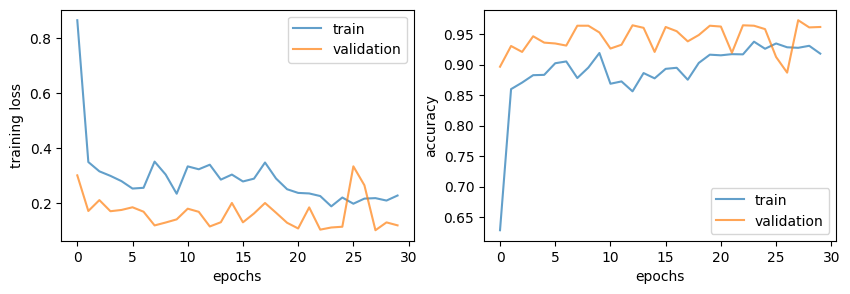

In [7]:
import matplotlib.pyplot as plt

fig,axs=plt.subplots(1,2,figsize=(10,3))
axs[0].plot(history.history["loss"],label="train",alpha=0.7)
axs[0].plot(history.history["val_loss"],label="validation",alpha=0.7)
axs[0].set_xlabel("epochs")
axs[0].set_ylabel("training loss")
axs[0].legend()

axs[1].plot(history.history["accuracy"],label="train",alpha=0.7)
axs[1].plot(history.history["val_accuracy"],label="validation",alpha=0.7)
axs[1].set_xlabel("epochs")
axs[1].set_ylabel("accuracy")
axs[1].legend()

# ...and with cosine annealing

Next, we repeat the training but this time use cosine annealing for the learning rate.

## Task:
* Find out how to do cosine annealing with tensorflow. If you do not know how, ask an AI.
* Cosine annealing will need to parameters, an initial learning rate <code>initial_learning_rate</code> and a parameter that basically fixes the minimum learning rate <code>alpha</code>. Use the settings provided in the cells below.
* Train a neural network with the same parameters as above but with cosine annealing learning rate. (That is, use <code>setup_model</code> and <code>model_compile</code> from above.)
* Report test accuracy and plot training loss, validation loss, training accuracy and validation accuracy.

Epoch 1/30
Epoch 2/30
Epoch 3/30
Epoch 4/30
Epoch 5/30
Epoch 6/30
Epoch 7/30
Epoch 8/30
Epoch 9/30
Epoch 10/30
Epoch 11/30
Epoch 12/30
Epoch 13/30
Epoch 14/30
Epoch 15/30
Epoch 16/30
Epoch 17/30
Epoch 18/30
Epoch 19/30
Epoch 20/30
Epoch 21/30
Epoch 22/30
Epoch 23/30
Epoch 24/30
Epoch 25/30
Epoch 26/30
Epoch 27/30
Epoch 28/30
Epoch 29/30
Epoch 30/30

Test Accuracy: 0.9735
Test Loss: 0.0579


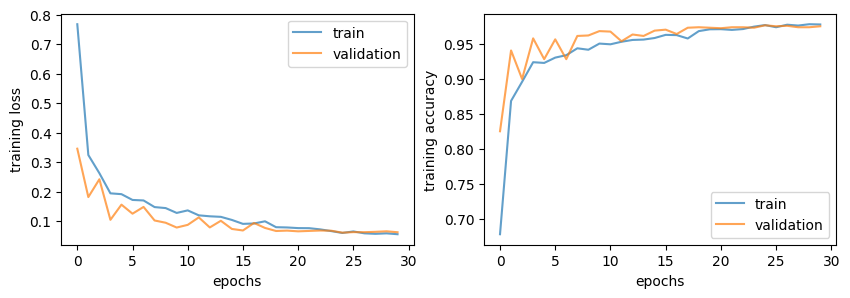

In [9]:
# found by hyperparameter tuning
best_initial_lr = 0.003
alpha = 0.01

### insert your code here ####
import math

steps_per_epoch = math.ceil(len(X_train) * 0.8 / batch_size)   # ceil(7209*0.8/64) = 91
decay_steps = epochs * steps_per_epoch                          # 30 * 91 = 2730

#Cosine annealing
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=best_initial_lr,   # 起点 0.003
    decay_steps=decay_steps,                 # 2730 步降到底
    alpha=alpha                              # 最低值 = 0.01 × 0.003 = 0.00003
)

model_cos = setup_model()
model_compile(model_cos, lr_schedule)

# Training
history = model_cos.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2, # Hold out 20% of the training data for validation
    verbose="0"
)

# Evaluation on the test set
test_loss_cos, test_accuracy_cos = model_cos.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_accuracy_cos:.4f}")
print(f"Test Loss: {test_loss_cos:.4f}")

#plot training loss, validation loss, training accuracy and validation accuracy.
fig,axs=plt.subplots(1,2,figsize=(10,3))
axs[0].plot(history.history["loss"],label="train",alpha=0.7)
axs[0].plot(history.history["val_loss"],label="validation",alpha=0.7)
axs[0].set_xlabel("epochs")
axs[0].set_ylabel("training loss")
axs[0].legend()

axs[1].plot(history.history["accuracy"],label="train",alpha=0.7)
axs[1].plot(history.history["val_accuracy"],label="validation",alpha=0.7)
axs[1].set_xlabel("epochs")
axs[1].set_ylabel("training accuracy")
axs[1].legend()

# Compare constant to cosine

One training run doesn't tell us much about any difference between constant learning rate and cosine annealing as the result could just be a statistical fluke. Let's repeat training several times and compare the means of training loss and accuracy.

## Task:
* write a loop that runs 5 times (you can run more often, but then it will take more time)
* in each iteration: draw a random train / test split via <code>get_train_test_split</code> above, train a model with constant learning rate, and one with cosine annealing, and record the training loss curve, the training accuracy curve and the test accuracy
* for constant learning rate and cosine annealing separately, compute the means over the loop iterations of training loss curve, training accuracy curve and test accuracy
* plot the means of training loss and training accuracy and report the means of test accuracy
* What do you observe?

Run 1/5
Epoch 1/30
Epoch 2/30
Epoch 3/30
Epoch 4/30
Epoch 5/30
Epoch 6/30
Epoch 7/30
Epoch 8/30
Epoch 9/30
Epoch 10/30
Epoch 11/30
Epoch 12/30
Epoch 13/30
Epoch 14/30
Epoch 15/30
Epoch 16/30
Epoch 17/30
Epoch 18/30
Epoch 19/30
Epoch 20/30
Epoch 21/30
Epoch 22/30
Epoch 23/30
Epoch 24/30
Epoch 25/30
Epoch 26/30
Epoch 27/30
Epoch 28/30
Epoch 29/30
Epoch 30/30
Epoch 1/30
Epoch 2/30
Epoch 3/30
Epoch 4/30
Epoch 5/30
Epoch 6/30
Epoch 7/30
Epoch 8/30
Epoch 9/30
Epoch 10/30
Epoch 11/30
Epoch 12/30
Epoch 13/30
Epoch 14/30
Epoch 15/30
Epoch 16/30
Epoch 17/30
Epoch 18/30
Epoch 19/30
Epoch 20/30
Epoch 21/30
Epoch 22/30
Epoch 23/30
Epoch 24/30
Epoch 25/30
Epoch 26/30
Epoch 27/30
Epoch 28/30
Epoch 29/30
Epoch 30/30
  constant: 0.9521 | cosine: 0.9770
Run 2/5
Epoch 1/30
Epoch 2/30
Epoch 3/30
Epoch 4/30
Epoch 5/30
Epoch 6/30
Epoch 7/30
Epoch 8/30
Epoch 9/30
Epoch 10/30
Epoch 11/30
Epoch 12/30
Epoch 13/30
Epoch 14/30
Epoch 15/30
Epoch 16/30
Epoch 17/30
Epoch 18/30
Epoch 19/30
Epoch 20/30
Epoch 21/30
Epo

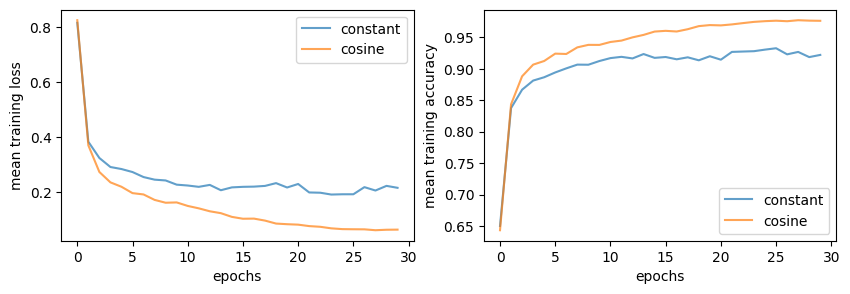

In [13]:
### insert your code here ###

n_runs = 5

# empty lists
constant_train_loss = []
constant_train_acc = []
constant_test_acc = []

cosine_train_loss = []
cosine_train_acc = []
cosine_test_acc = []

#loop
for run in range(n_runs):
    print(f"Run {run + 1}/{n_runs}")
    #draw a random train / test split
    X_train, X_test, y_train, y_test = get_train_test_split()
    #train a model with constant learning rate
    model = setup_model()
    model_compile(model, best_constant_lr)
    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2, # Hold out 20% of the training data for validation
        verbose="0")
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
    constant_train_loss.append(history.history["loss"])
    constant_train_acc.append(history.history["accuracy"])
    constant_test_acc.append(test_accuracy)

    #train a model with cosine annealing
    steps_per_epoch = math.ceil(len(X_train) * 0.8 / batch_size)   # ceil(7209*0.8/64) = 91
    decay_steps = epochs * steps_per_epoch                          # 30 * 91 = 2730

#Cosine annealing
    lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=best_initial_lr,   # 起点 0.003
    decay_steps=decay_steps,                 # 2730 步降到底
    alpha=alpha                              # 最低值 = 0.01 × 0.003 = 0.00003
)
    model_cos = setup_model()
    model_compile(model_cos, lr_schedule)
    history = model_cos.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2, # Hold out 20% of the training data for validation
    verbose="0"
)

# Evaluation on the test set
    test_loss_cos, test_accuracy_cos = model_cos.evaluate(X_test, y_test, verbose=0)
    cosine_train_loss.append(history.history["loss"])
    cosine_train_acc.append(history.history["accuracy"])
    cosine_test_acc.append(test_accuracy_cos)

    print(f"  constant: {test_accuracy:.4f} | cosine: {test_accuracy_cos:.4f}")

#compute the means
constant_train_loss_mean = np.mean(constant_train_loss, axis=0)
constant_train_acc_mean  = np.mean(constant_train_acc,  axis=0)
cosine_train_loss_mean   = np.mean(cosine_train_loss,   axis=0)
cosine_train_acc_mean    = np.mean(cosine_train_acc,    axis=0)

#plot the means of training loss and training accuracy
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(constant_train_loss_mean, label="constant", alpha=0.7)
axs[0].plot(cosine_train_loss_mean,   label="cosine",   alpha=0.7)
axs[0].set_xlabel("epochs")
axs[0].set_ylabel("mean training loss")
axs[0].legend()

axs[1].plot(constant_train_acc_mean, label="constant", alpha=0.7)
axs[1].plot(cosine_train_acc_mean,   label="cosine",   alpha=0.7)
axs[1].set_xlabel("epochs")
axs[1].set_ylabel("mean training accuracy")
axs[1].legend()

#report the means of test accuracy(+ standard deviation)
print(f"Mean test accuracy constant: {np.mean(constant_test_acc):.4f} ± {np.std(constant_test_acc):.4f}")
print(f"Mean test accuracy cosine:   {np.mean(cosine_test_acc):.4f} ± {np.std(cosine_test_acc):.4f}")

What do you observe?
1.the first two epochs both methods
behave almost identically，afterwards the curves separate.
2.combine the two figures, cosine is more stable than constant.

